# 01 · Primera simulación de kinesina-1

Construiremos un motor, definiremos el ambiente, inspeccionaremos su red y ejecutaremos una trayectoria estocástica con Gillespie. Este notebook sirve como punto de entrada a la API.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


## 1. Importar las herramientas

In [2]:
import matplotlib.pyplot as plt

from protein_motor_sim import Environment, GillespieSimulator, Kinesin1
from protein_motor_sim.analysis.observables import analyze_trajectory
from protein_motor_sim.visualization.plots import plot_trajectory

## 2. Definir el experimento

La fuerza está expresada en newtons, la temperatura en kelvin y la concentración de ATP en mol/L.

In [3]:
motor = Kinesin1()
environment = Environment(
    atp_concentration=1.0e-3,  # 1 mM
    external_force_N=0.0,      # sin carga externa
    temperature_K=310.0,
)
simulator = GillespieSimulator()

print("Motor:", motor.name)
print("Tamaño de paso nominal (nm):", motor.step_size_nm)
print("Ambiente:", environment)

Motor: Kinesin-1
Tamaño de paso nominal (nm): 8.2
Ambiente: Environment(atp_concentration=0.001, external_force_N=0.0, temperature_K=310.0)


## 3. Ejecutar una trayectoria

La semilla garantiza que el resultado sea reproducible con la misma versión del código y las mismas dependencias.

In [4]:
trajectory = simulator.run(
    motor=motor,
    environment=environment,
    t_max=1.0,
    seed=42,
)

summary = analyze_trajectory(trajectory)
print(summary)
print("Número de registros:", len(trajectory.times_s))
print("Estado final:", trajectory.final_state)
print("ATP consumido:", trajectory.atp_consumed_total)

TrajectoryAnalysis(velocity_nm_s=319.7999999999998, run_length_nm=319.7999999999998, path_length_nm=319.7999999999998, duration_s=1.0, atp_consumed=40, forward_steps=39, backward_steps=0, detached=False)
Número de registros: 121
Estado final: post_hydrolysis
ATP consumido: 40


## 4. Graficar la posición

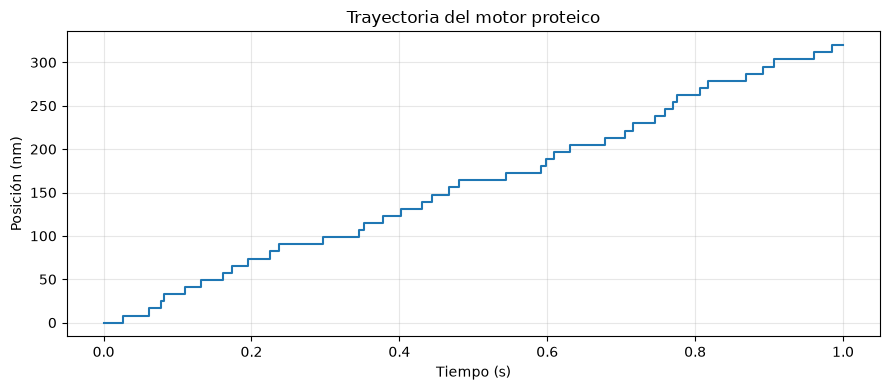

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_trajectory(trajectory, ax=ax)
plt.tight_layout()
plt.show()

## 5. Interpretación

La curva es una trayectoria de una única realización aleatoria. Para obtener promedios representativos hay que repetir el experimento muchas veces; eso se estudia en los notebooks 04–06. Si la simulación termina por alcanzar `t_max` y no por desprendimiento, el recorrido observado está censurado por la ventana temporal.